## Task 1 

<div dir="rtl">

### فهم المشكلة

**1. ما السؤال الذي تريد الشركة الإجابة عنه؟**
الشركة تريد تعرف أي العملاء عندهم احتمال أكبر يتركون الخدمة، حتى تقدر تتصرف بدري وتحافظ عليهم

**2. ما هو الـ Target؟**
الـ Target هو عمود `Churn`:
- **Yes**: العميل ترك الشركة
- **No**: العميل ما زال مستمر مع الشركة

**3. من يستفيد من الجواب؟**
تستفيد إدارة الشركة وفرق التسويق وخدمة العملاء، لانهم يقدرون يحددون العملاء المعرضين لترك الخدمة ويتخذون إجراءات للاحتفاظ بهم

**ملاحظة:** تحتوي البيانات على 7,043 عميل

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.shape)
print(df.dtypes)
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Churn"].value_counts())
df.head()

(7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<div dir="rtl">

### ملاحظات أولية على البيانات

- تحتوي البيانات على 7,043 صف و21 عمود، مما يعني أن حجم البيانات مناسب للتحليل وبناء نموذج للتنبؤ
- لا توجد قيم مفقودة (`NaN`) ولا صفوف مكررة (Duplicate Rows)، لكن فيه قيم فارغة مخفية (سيأتي ذكرها بالأسفل)
- توزيع متغير `Churn` غير متوازن، بحيث يوجد 5,174 عميل مستمر مع الشركة (`No`) مقابل 1,869 عميل ترك الخدمة (`Yes`)، يعني نسبة العملاء اللي تركوا الخدمة تقارب 26.5%
- لوحظ أن عمود `TotalCharges` مخزن كنوع بيانات نصي (`Object`) رغم أن قيمه تمثل مبالغ رقمية، لذلك يحتاج تحويله إلى نوع رقمي قبل استخدامه في التحليل أو النمذجة

</div>

In [2]:
total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(total_num.isnull().sum())
print(df.loc[total_num.isnull(), ["tenure", "TotalCharges"]])

print(df["MultipleLines"].value_counts())
print(df["OnlineSecurity"].value_counts())

11
      tenure TotalCharges
488        0             
753        0             
936        0             
1082       0             
1340       0             
3331       0             
3826       0             
4380       0             
5218       0             
6670       0             
6754       0             
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64


<div dir="rtl">

### ملاحظات إضافية من أول نظرة على البيانات

- يوجد 11 صف يحتوي عمود `TotalCharges` فيها على قيمة فارغة، وجميع هذي الحالات لديها `tenure = 0`، مما يدل على انهم عملاء جدد وما صدرت لهم أي فواتير بعد
- لوحظ أن عمود `MultipleLines` ما يحتوي على قيمتي `Yes` و `No` فقط، بل يحتوي أيضا على القيمة `No phone service` بعدد 682 سجل، لذلك فهو مو عمود ثنائي القيم بالكامل
- كذلك يحتوي عمود `OnlineSecurity` على قيمة إضافية وهي `No internet service` بعدد 1,526 سجل، إضافة إلى القيمتين `Yes` و `No`، مما يستدعي الانتباه لها أثناء مرحلة التنظيف وتجهيز البيانات

</div>

<div dir="rtl">

### توقع قبل الرسم

- أتوقع تكون نسبة ترك الخدمة هي الأعلى عند العملاء اللي عندهم عقد شهري (`Month-to-month`)، وممكن توصل لحوالي 60% إلى 70%، لان هذا النوع يعطي العميل مرونة أكبر في إلغاء الخدمة بأي وقت
- أما العملاء اللي عندهم عقد سنة (`One year`)، أتوقع تكون نسبة الترك عندهم أقل وتكون حوالي 10% إلى 15%، لانهم ملتزمين بعقد لمدة سنة كاملة
- وبالنسبة لعقود السنتين (`Two year`)، أتوقع تكون نسبة الترك هي الأقل وتكون تحت 10%، بسبب ارتباط العميل بعقد طويل المدة وصعوبة الانتقال لشركة ثانية خلال فترة العقد

بشكل عام، أتوقع وجود علاقة عكسية بين مدة العقد ونسبة ترك الخدمة، بحيث كل ما زادت مدة الالتزام بالعقد انخفضت احتمالية ترك العميل للخدمة

</div>

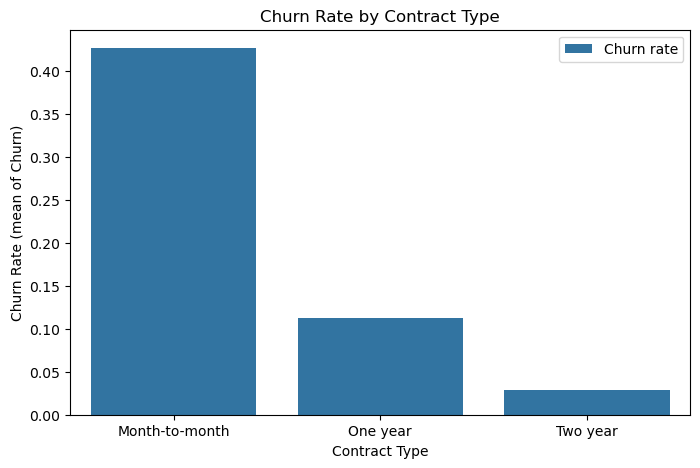

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64


In [3]:
churn_num = (df["Churn"] == "Yes").astype(int)   # Yes = 1 ، No = 0

plt.figure(figsize=(8, 5))
sns.barplot(x=df["Contract"], y=churn_num, errorbar=None,
            order=["Month-to-month", "One year", "Two year"],
            label="Churn rate")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (mean of Churn)")
plt.legend()
plt.show()

print(churn_num.groupby(df["Contract"]).mean())

<div dir="rtl">

### النتائج والملاحظات

- أظهرت النتائج أن أعلى نسبة ترك للخدمة كانت لدى العملاء أصحاب العقود الشهرية (`Month-to-month`) بنسبة 42.7%
- انخفضت النسبة بشكل واضح لدى العملاء أصحاب عقود السنة (`One year`) إلى 11.3%
- كانت أقل نسبة ترك للخدمة لدى العملاء أصحاب عقود السنتين (`Two year`) حيث بلغت 2.8%

بالمقارنة مع التوقع قبل الرسم، كان التوقع صحيح فيما يتعلق بالاتجاه العام، بحيث كل ما زادت مدة العقد انخفضت نسبة ترك الخدمة. كما كان التوقع قريب من النسب الفعلية لكنه غير دقيق لعقود السنة والسنتين، بينما توقع نسبة الترك لدى عملاء العقود الشهرية (`Month-to-month`) كان غير صحيح، حيث كانت النسبة الفعلية 42.7% وليس كما توقعت في البداية ( 60% إلى 70%)

تشير هذه النتيجة إلى أن نوع العقد يعد من العوامل المهمة المرتبطة بترك الخدمة، حيث يبدو أن العملاء المرتبطين بعقود أطول أكثر استقرار وأقل عرضة للمغادرة

</div>

<div dir="rtl">

### توقع قبل الرسم

- أتوقع يكون وسيط مدة الاشتراك (`tenure`) عند العملاء اللي تركوا الخدمة (`Yes`) حوالي 10 إلى 15 شهر، بينما يكون عند العملاء المستمرين (`No`) حوالي 35 إلى 45 شهر
- أتوقع يكون وسيط الفاتورة الشهرية (`MonthlyCharges`) عند العملاء اللي تركوا الخدمة حوالي 80 إلى 90 دولار، بينما يكون عند العملاء المستمرين حوالي 60 إلى 70 دولار


</div>

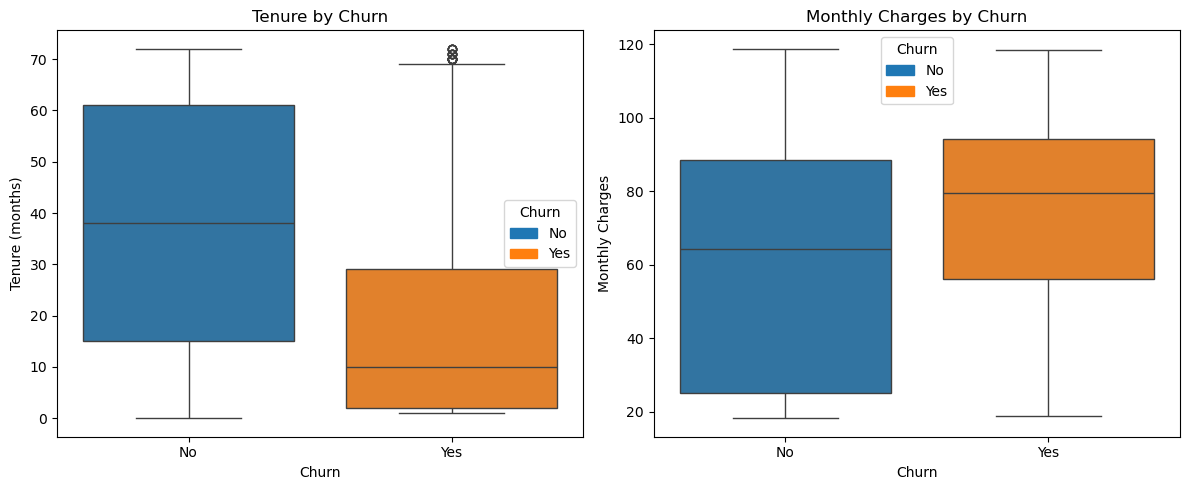

       tenure  MonthlyCharges
Churn                        
No       38.0          64.425
Yes      10.0          79.650


In [4]:
from matplotlib.patches import Patch

colors = sns.color_palette()
handles = [Patch(color=colors[0], label="No"), Patch(color=colors[1], label="Yes")]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", ax=axes[0])
axes[0].set_title("Tenure by Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")
axes[0].legend(handles=handles, title="Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly Charges")
axes[1].legend(handles=handles, title="Churn")

plt.tight_layout()
plt.show()

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median())

<div dir="rtl">

### النتائج والملاحظات

- ظهرت النتائج أن وسيط مدة الاشتراك (`tenure`) لدى العملاء اللي تركوا الخدمة (`Yes`) يساوي 10 أشهر فقط، بينما بلغ 38 شهر لدى العملاء المستمرين (`No`)
- ايضا أن وسيط الفاتورة الشهرية (`MonthlyCharges`) لدى العملاء اللي تركوا الخدمة بلغ 79.65، بينما كان 64.43 لدى العملاء المستمرين

بالمقارنة مع التوقع قبل الرسم، كانت التوقعات قريبة من النتائج الفعلية فقد توقعت يكون وسيط مدة الاشتراك لدى العملاء التاركين بين 10 و15 شهر، وكانت القيمة الفعلية 10 أشهر. كذلك توقعت يكون وسيط مدة الاشتراك لدى العملاء المستمرين بين 35 و45 شهر، وكانت القيمة الفعلية 38 شهر

لكن بالنسبة للفاتورة الشهرية، فكان التوقع قريب أيضا، بحيث بلغ الوسيط الفعلي 79.65 لدى العملاء التاركين (توقعت بين 80 و90) و64.43 لدى العملاء المستمرين (توقعت بين 60 و70)

تشير هذه النتائج إلى أن العملاء اللي يتركون الخدمة غالبا ما تكون مدة اشتراكهم أقصر، كما انهم يدفعون رسوم شهرية أعلى مقارنة بالعملاء المستمرين، مما يجعل مدة الاشتراك وقيمة الفاتورة الشهرية من المتغيرات المهمة المرتبطة بترك الخدمة

</div>

In [5]:
for col in df.select_dtypes("object").columns:
    if col not in ["customerID", "TotalCharges"]:
        print(col, df[col].unique())

print(df["SeniorCitizen"].unique())

gender ['Female' 'Male']
Partner ['Yes' 'No']
Dependents ['No' 'Yes']
PhoneService ['No' 'Yes']
MultipleLines ['No phone service' 'No' 'Yes']
InternetService ['DSL' 'Fiber optic' 'No']
OnlineSecurity ['No' 'Yes' 'No internet service']
OnlineBackup ['Yes' 'No' 'No internet service']
DeviceProtection ['No' 'Yes' 'No internet service']
TechSupport ['No' 'Yes' 'No internet service']
StreamingTV ['No' 'Yes' 'No internet service']
StreamingMovies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'One year' 'Two year']
PaperlessBilling ['Yes' 'No']
PaymentMethod ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn ['No' 'Yes']
[0 1]


In [6]:
print((df["InternetService"] == "No").sum())
print((df["PhoneService"] == "No").sum())

1526
682


<div dir="rtl">

### Decision Log

**1. مشكلة `TotalCharges`**
- **المشكلة:** يوجد 11 صف يحتوي عمود `TotalCharges` فيها على فراغات، وتمثل حوالي 0.16% من البيانات، وجميعها لديها `tenure = 0`
- **القرار:** تعويض القيم الفارغة بالقيمة 0 ثم تحويل العمود إلى نوع رقمي
- **السبب:** العملاء جدد وما صدرت لهم أي فواتير بعد، لذلك القيمة 0 تمثل حالتهم الفعلية وتحافظ على جميع السجلات بدون فقدان بيانات

**2. مشكلة `MultipleLines`**
- **المشكلة:** يحتوي العمود على القيمة `No phone service` بعدد 682 سجل بالإضافة إلى `Yes` و `No`
- **القرار:** دمج `No phone service` مع `No`
- **السبب:** تبين ان عدد العملاء اللي عندهم القيمة `No phone service` يساوي عدد العملاء اللي عندهم `PhoneService = No` (682 عميل)، مما يدل على ان هذي القيمة مجرد تكرار لمعلومة موجودة مسبقا في عمود `PhoneService` وما تضيف معلومة جديدة للتحليل

**3. مشكلة `No internet service` في الأعمدة المرتبطة بالإنترنت**
- **الأعمدة المتأثرة:** `OnlineSecurity`، `OnlineBackup`، `DeviceProtection`، `TechSupport`، `StreamingTV`، `StreamingMovies`
- **المشكلة:** تحتوي هذي الأعمدة على القيمة `No internet service` بالإضافة إلى `Yes` و `No`
- **القرار:** دمج `No internet service` مع `No` في جميع الأعمدة الستة
- **السبب:** تبين ان عدد العملاء اللي عندهم `InternetService = No` هو 1,526 عميل، وهو نفس عدد ظهور القيمة `No internet service` في هذي الأعمدة. هذا يعني ان القيمة ما تضيف معلومة جديدة، بل تكرر معلومة موجودة مسبقا في عمود `InternetService`، لذلك تم دمجها مع `No` لتبسيط البيانات وتقليل عدد الفئات بدون فقدان معلومات مهمة

**4. عمود `SeniorCitizen`**
- **المشكلة:** يمثل العمود حالة العميل الكبير في السن باستخدام القيم الرقمية 0 و 1
- **القرار:** الإبقاء على العمود كما هو بدون تعديل
- **السبب:** العمود مخزن بالفعل بصيغة رقمية مناسبة للنماذج، بحيث تمثل القيمة 1 العميل الكبير في السن وتمثل القيمة 0 غير ذلك. لذلك ما فيه حاجة لتحويله إلى قيم نصية أو إجراء أي تعديل إضافي عليه

</div>

In [7]:
df_clean = df.copy()

# 1) TotalCharges: الفراغ -> 0 ثم تحويل لرقم
df_clean["TotalCharges"] = df_clean["TotalCharges"].str.strip().replace("", "0")
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"])

# 2) MultipleLines
df_clean["MultipleLines"] = df_clean["MultipleLines"].replace("No phone service", "No")

# 3) أعمدة الخدمات الست
internet_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
for col in internet_cols:
    df_clean[col] = df_clean[col].replace("No internet service", "No")

print(df_clean["TotalCharges"].dtype, df_clean["TotalCharges"].isnull().sum())
print(df_clean["MultipleLines"].value_counts())
print(df_clean["OnlineSecurity"].value_counts())
print(df_clean.shape)

df_clean.to_csv("telco_clean.csv", index=False)

float64 0
MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64
OnlineSecurity
No     5024
Yes    2019
Name: count, dtype: int64
(7043, 21)


<div dir="rtl">

### نتائج التنظيف

- تم تحويل عمود `TotalCharges` إلى نوع رقمي (`float64`) ومعالجة جميع القيم الفارغة، ليصبح عدد القيم المفقودة في العمود صفر
- تم دمج القيمة `No phone service` مع `No` في عمود `MultipleLines`، فأصبح عدد السجلات في فئة `No` يساوي 4,072 سجل (3,390 + 682)
- كما تم دمج القيمة `No internet service` مع `No` في الأعمدة المرتبطة بخدمات الإنترنت، وأصبح عدد السجلات في فئة `No` داخل عمود `OnlineSecurity` يساوي 5,024 سجل (3,498 + 1,526)
- لم يتم حذف أي صف من البيانات أثناء التنظيف، وبقي حجم البيانات كما هو: 7,043 صف و21 عمود

</div>

<div dir="rtl">

### Feature Engineering (القرار)

**1. `Tenure_Group`**
سيتم إنشاء عمود جديد باسم `Tenure_Group` لتقسيم العملاء إلى فئات حسب مدة الاشتراك:
- **New**: من 0 إلى 12 شهر
- **Medium**: من 13 إلى 48 شهر
- **Loyal**: أكثر من 48 شهر

**السبب:** أظهرت نتائج التحليل أن وسيط مدة الاشتراك للعملاء اللي تركوا الخدمة هو 10 أشهر فقط، مقابل 38 شهر للعملاء المستمرين. لذلك تجميع مدة الاشتراك في فئات ممكن يساعد على إظهار الفرق بين العملاء الجدد والعملاء الأكثر استقرار بشكل أوضح.

**2. `Services_Count`**
سيتم إنشاء عمود جديد باسم `Services_Count` يمثل عدد الخدمات الإضافية اللي يشترك بها العميل من الأعمدة التالية:
- `OnlineSecurity`
- `OnlineBackup`
- `DeviceProtection`
- `TechSupport`
- `StreamingTV`
- `StreamingMovies`

وسيتم احتساب كل قيمة `Yes` على أنها 1، ثم جمعها للحصول على إجمالي عدد الخدمات لكل عميل.

**السبب:** كل ما زاد عدد الخدمات اللي يستخدمها العميل، زاد ارتباطه بالشركة وصار الانتقال إلى شركة ثانية أصعب. لذلك ممكن يكون عدد الخدمات المشترك بها مؤشر مفيد للتنبؤ بترك الخدمة.

</div>

In [8]:
df_fe = df_clean.copy()

# 1) Tenure_Group
df_fe["Tenure_Group"] = pd.cut(df_fe["tenure"],
                               bins=[-1, 12, 48, 72],
                               labels=["New", "Medium", "Loyal"])

# 2) Services_Count
services_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]
df_fe["Services_Count"] = (df_fe[services_cols] == "Yes").sum(axis=1)

print(df_fe["Tenure_Group"].value_counts())
print(df_fe["Services_Count"].value_counts().sort_index())
print(df_fe[["tenure", "Tenure_Group", "Services_Count"]].head())

Tenure_Group
Medium    2618
Loyal     2239
New       2186
Name: count, dtype: int64
Services_Count
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64
   tenure Tenure_Group  Services_Count
0       1          New               1
1      34       Medium               2
2       2          New               2
3      45       Medium               3
4       2          New               0


<div dir="rtl">

### توقع قبل الرسم

**1. توقع نسبة المغادرة حسب `Tenure_Group`**
- أتوقع تكون أعلى نسبة مغادرة في فئة `New` (من 0 إلى 12 شهر)، وممكن تكون بين 40% و50%، لان التحليل السابق أظهر ان وسيط مدة الاشتراك لدى العملاء اللي تركوا الخدمة هو 10 أشهر فقط
- أما فئة `Medium` (من 13 إلى 48 شهر)، فأتوقع تكون نسبة المغادرة فيها متوسطة وتتراوح بين 15% و25%
- وأتوقع تكون أقل نسبة مغادرة في فئة `Loyal` (أكثر من 48 شهر)، وممكن تكون أقل من 10% بسبب طول مدة ارتباطهم بالشركة

**2. توقع نسبة المغادرة حسب `Services_Count`**
- أتوقع ترتفع نسبة المغادرة كل ما زاد عدد الخدمات الإضافية اللي يشترك بها العميل
- أتوقع تكون نسبة المغادرة الأقل عند العملاء اللي ما عندهم أي خدمات إضافية أو خدمة واحدة فقط، بينما تكون أعلى عند العملاء اللي عندهم عدد كبير من الخدمات مثل 5 أو 6 خدمات

**السبب:** زيادة عدد الخدمات ممكن ترفع التكلفة الشهرية على العميل، وهذا ممكن يدفع بعض العملاء لإلغاء الخدمة والانتقال لبدائل ثانية.

</div>

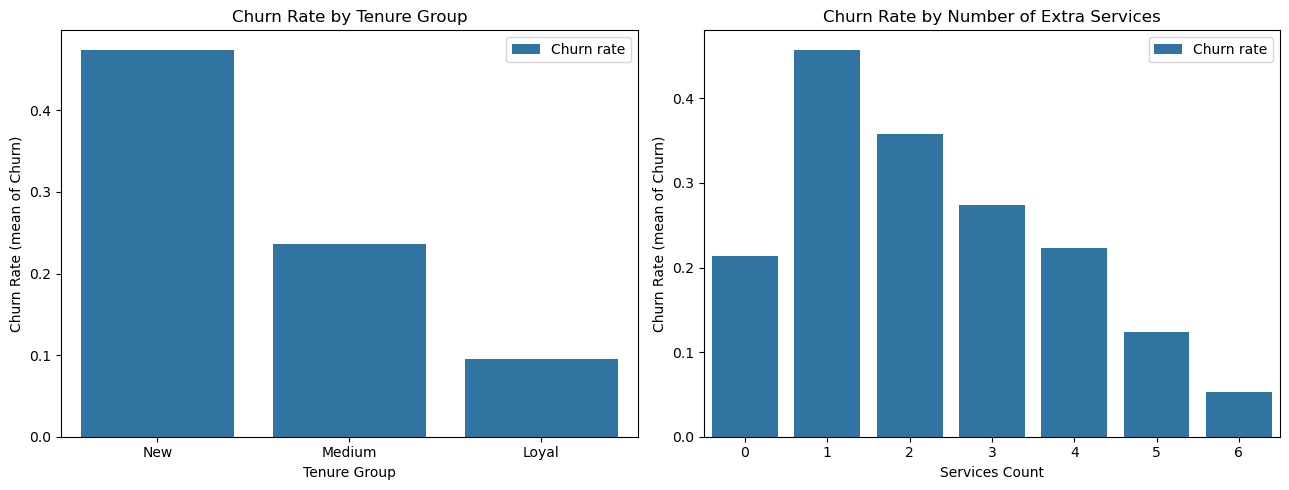

Tenure_Group
New       0.474382
Medium    0.236440
Loyal     0.095132
Name: Churn, dtype: float64
Services_Count
0    0.214060
1    0.457557
2    0.358180
3    0.273703
4    0.223005
5    0.124343
6    0.052817
Name: Churn, dtype: float64


In [9]:
churn_num = (df_fe["Churn"] == "Yes").astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(x=df_fe["Tenure_Group"], y=churn_num, errorbar=None,
            order=["New", "Medium", "Loyal"], label="Churn rate", ax=axes[0])
axes[0].set_title("Churn Rate by Tenure Group")
axes[0].set_xlabel("Tenure Group")
axes[0].set_ylabel("Churn Rate (mean of Churn)")
axes[0].legend()

sns.barplot(x=df_fe["Services_Count"], y=churn_num, errorbar=None,
            label="Churn rate", ax=axes[1])
axes[1].set_title("Churn Rate by Number of Extra Services")
axes[1].set_xlabel("Services Count")
axes[1].set_ylabel("Churn Rate (mean of Churn)")
axes[1].legend()

plt.tight_layout()
plt.show()

print(churn_num.groupby(df_fe["Tenure_Group"], observed=False).mean())
print(churn_num.groupby(df_fe["Services_Count"]).mean())

In [10]:
zero_services = df_fe[df_fe["Services_Count"] == 0]
print(zero_services["InternetService"].value_counts())
print(churn_num[zero_services.index].groupby(zero_services["InternetService"]).mean())

InternetService
No             1526
Fiber optic     399
DSL             294
Name: count, dtype: int64
InternetService
DSL            0.411565
Fiber optic    0.604010
No             0.074050
Name: Churn, dtype: float64


<div dir="rtl">

## النتائج والتوصيات والملاحظات (الرسمتين)

### 1. `Tenure_Group`

- جاءت النتائج متوافقة مع التوقع بشكل كبير
- سجلت فئة `New` أعلى نسبة مغادرة بلغت 47.4%، بعدها فئة `Medium` بنسبة 23.6%، بينما سجلت فئة `Loyal` أقل نسبة مغادرة بلغت 9.5%
- تشير هذه النتائج أن مدة الاشتراك عامل مهم في ترك الخدمة، وتنخفض احتمالية المغادرة كل ما زادت مدة بقاء العميل مع الشركة

### 2. `Services_Count`

- توقعي في هذه الحالة غير صحيح توقعت ترتفع نسبة المغادرة مع زيادة عدد الخدمات، لكن النتائج أظهرت العكس.
- بشكل عام، انخفضت نسبة المغادرة كل ما زاد عدد الخدمات الإضافية لدى العميل، حيث بلغت 45.8% عند العملاء اللي عندهم خدمة واحدة فقط، وانخفضت تدريجيا حتى وصلت إلى 5.3% عند العملاء اللي عندهم 6 خدمات
- تشير هذه النتيجة إلى أن العملاء المشتركين في عدد أكبر من الخدمات يكونون أكثر ارتباط بالشركة وأقل ميل لترك الخدمة، وهذا يدعم فكرة إنشاء المتغير `Services_Count`

**ملاحظة مهمة:**

- والعملاء الي عندهم 0 خدمات إضافية سجلوا نسبة مغادرة قدرها 21.4%، وهي أقل من العملاء اللي عندهم خدمة واحدة (45.8%) رغم الاتجاه

<div dir="rtl">

### توقع قبل تحليل الارتباط

**أقوى الارتباطات الموجبة المتوقعة مع `Churn`:**
1. **`Contract_Month-to-month`**: ارتباط موجب يقارب +0.3 إلى +0.5، لانه حقق أعلى نسبة مغادرة في التحليل السابق
2. **`MonthlyCharges`**: ارتباط موجب يقارب +0.2 إلى +0.4، لان العملاء أصحاب الفواتير الأعلى كانوا أكثر عرضة للمغادرة
3. **`InternetService_Fiber optic`**: ارتباط موجب يقارب +0.2 إلى +0.3، بسبب ارتفاع معدل المغادرة عند هذه الفئة

**أقوى الارتباطات السالبة المتوقعة مع `Churn`:**
1. **`tenure`**: ارتباط سالب يقارب -0.3 إلى -0.5، لان العملاء الي يغادرون مدة اشتراكهم أقصر بكثير
2. **`Contract_Two year`**: ارتباط سالب يقارب -0.3 إلى -0.5، لان نسبة المغادرة فيها كانت منخفضة جدا
3. **`Services_Count`**: ارتباط سالب يقارب -0.2 إلى -0.4، لان العملاء الي عندهم خدمات أكثر كانوا أقل مغادرة في التحليل السابق

وأتوقع يكون أقوى ارتباط في البيانات هو **`tenure`** بقيمة تقارب **-0.5**.

</div>

In [11]:
df_model = df_fe.drop(columns=["customerID"])
df_model["Churn"] = (df_model["Churn"] == "Yes").astype(int)
df_model["gender"] = (df_model["gender"] == "Male").astype(int)

yes_no_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling",
               "MultipleLines"] + internet_cols
for col in yes_no_cols:
    df_model[col] = (df_model[col] == "Yes").astype(int)

df_model = pd.get_dummies(df_model,
                          columns=["InternetService", "Contract", "PaymentMethod", "Tenure_Group"],
                          dtype=int)

print(df_model.shape)
print(df_model.dtypes.value_counts())
print(df_model.isnull().sum().sum())

(7043, 31)
int32      26
int64       3
float64     2
Name: count, dtype: int64
0


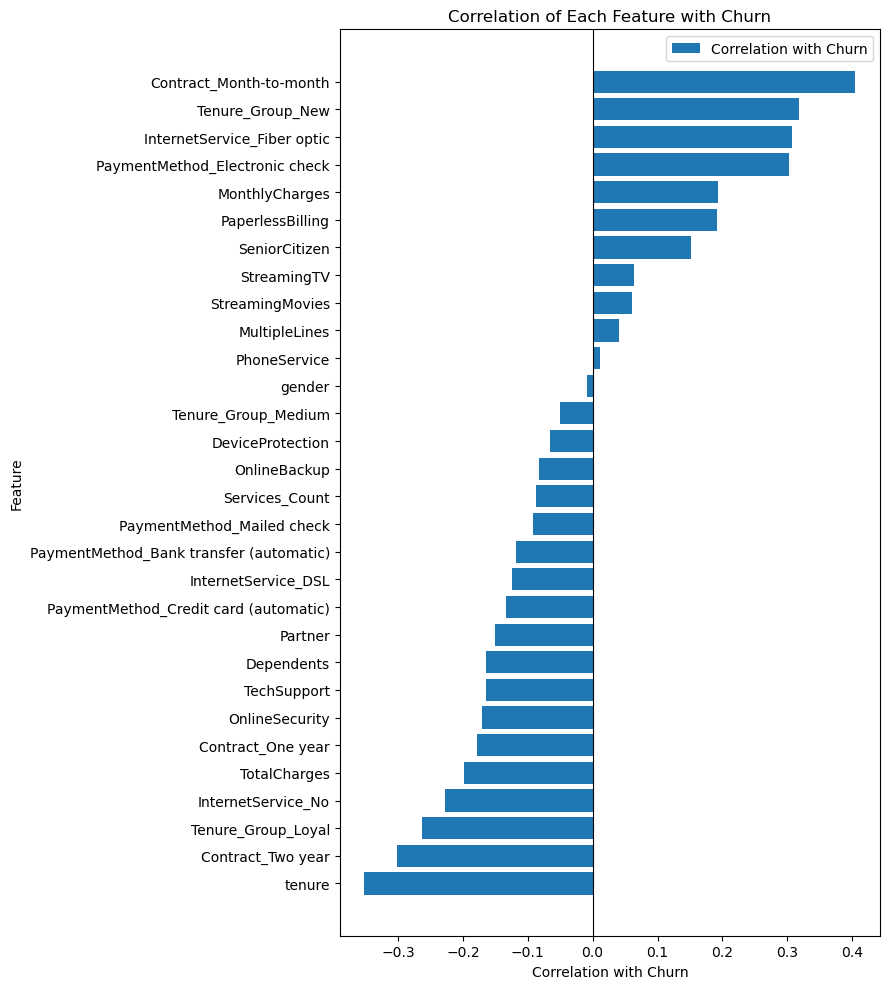

tenure                                    -0.352
Contract_Two year                         -0.302
Tenure_Group_Loyal                        -0.263
InternetService_No                        -0.228
TotalCharges                              -0.198
Contract_One year                         -0.178
OnlineSecurity                            -0.171
TechSupport                               -0.165
Dependents                                -0.164
Partner                                   -0.150
PaymentMethod_Credit card (automatic)     -0.134
InternetService_DSL                       -0.124
PaymentMethod_Bank transfer (automatic)   -0.118
PaymentMethod_Mailed check                -0.092
Services_Count                            -0.088
OnlineBackup                              -0.082
DeviceProtection                          -0.066
Tenure_Group_Medium                       -0.050
gender                                    -0.009
PhoneService                               0.012
MultipleLines       

In [12]:
corr = df_model.corr()["Churn"].drop("Churn").sort_values()

plt.figure(figsize=(9, 10))
plt.barh(corr.index, corr.values, label="Correlation with Churn")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation of Each Feature with Churn")
plt.xlabel("Correlation with Churn")
plt.ylabel("Feature")
plt.legend()
plt.tight_layout()
plt.show()

print(corr.round(3))

# للتأكد من التكرار بين الأعمدة (للجدول)
print(df_model[["tenure", "TotalCharges", "MonthlyCharges", "Services_Count"]].corr().round(2))

<div dir="rtl">

### النتائج والملاحظات

ظهرت نتائج الارتباط أن أقوى ارتباط موجب مع `Churn` كان لمتغير `Contract_Month-to-month` بقيمة +0.405، بعده `Tenure_Group_New` بقيمة +0.318، ثم `InternetService_Fiber optic` بقيمة +0.308. وتشير هذه النتائج إلى أن العملاء الجدد وأصحاب العقود الشهرية وعملاء `Fiber optic` أكثر عرضة لترك الخدمة

لكن أقوى الارتباطات السالبة فكانت `tenure` بقيمة -0.352، ثم `Contract_Two year` بقيمة -0.302، ثم `Tenure_Group_Loyal` بقيمة -0.263، مما يدل على أن العملاء أصحاب الاشتراكات طويلة المدة أقل عرضة للمغادرة

بالمقارنة مع التوقعات السابقة، كانت معظم التوقعات صحيحة، حيث توقعت قوة تأثير عقد `Month-to-month` ومدة الاشتراك وعقد `Two year` بشكل قريب من النتائج الفعلية. ومع ذلك، توقعي لأقوى ارتباط كان غير صحيح لان أقوى ارتباط فعلي هو `Contract_Month-to-month` وليس `tenure` كما توقعت

كما لوحظ أن `Services_Count` يمتلك ارتباط خطي ضعيف نسبيا (-0.088) رغم أن الرسوم البيانية السابقة أظهرت علاقة واضحة بين عدد الخدمات ومعدل المغادرة. ويحتمل أن يكون السبب أن العلاقة ليست خطية بالكامل، بالإضافة إلى تأثير العملاء الي ما يملكون خدمة إنترنت أصلا ضمن فئة الصفر خدمات

أما أضعف المتغيرات ارتباط بالمغادرة فكانت `gender` (-0.009) و`PhoneService` (+0.012) و`MultipleLines` (+0.040)، مما يشير إلى أن تأثيرها المباشر على ترك الخدمة محدود جدا

</div>

<div dir="rtl">

### قاعدة اتخاذ القرار

بشكل عام، حذفت الأعمدة الي كان ارتباطها مع `Churn` ضعيف جدا (أقل من ±0.02 تقريبا)، إلا إذا كانت تمثل سلوك أو نمط مهم ظهر بوضوح في التحليل الاستكشافي (EDA) وما يمكن ملاحظته من الارتباط الخطي فقط

### Feature Selection Decisions

| العمود | القرار | السبب |
| :--- | :---: | :--- |
| **customerID** | Drop | معرف فريد للعميل ويحتوي على 7,043 قيمة فريدة، لذلك ما يحمل قيمة تنبؤية للنموذج |
| **gender** | Drop | ارتباطه مع `Churn` ضعيف (-0.009)، وأقل من الحد المعتمد للاحتفاظ بالمتغيرات |
| **PhoneService** | Drop | ارتباطه شبه معدوم (+0.012)، وما يظهر تأثير واضح على المغادرة |
| **MultipleLines** | Keep | رغم ان ارتباطه منخفض (+0.040)، يمثل سلوك استخدام للخدمة وليس مجرد معلومة تعريفية، لذلك أبقيته للاختبار في النموذج |
| **TotalCharges** | Drop | ارتباطه مع `tenure` مرتفع جدا (0.83)، مما يدل على وجود تكرار كبير للمعلومات. كما أن `tenure` يمتلك ارتباط أقوى مع `Churn` (-0.352 مقابل -0.198) |
| **tenure** | Keep | من أقوى المتغيرات ارتباط بالمغادرة (-0.352)، كما أظهرت تحليلات EDA فرق واضح بين العملاء المغادرين والمستمرين |
| **Tenure_Group** | Drop | مشتق من `tenure` نفسه. كما أن قيمه (`New` = +0.318 و `Loyal` = -0.263) تعكس نفس النمط الموجود أصلا في `tenure` (-0.352) بدون إضافة معلومات جديدة، لذلك أبقيت الأصل وحذفت المشتق |
| **Services_Count** | Keep | رغم ان ارتباطه الخطي ضعيف نسبيا (-0.088)، أظهر الـ EDA نمط واضح لانخفاض المغادرة من 45.8% عند خدمة واحدة إلى 5.3% عند 6 خدمات. كما أن ضعف الارتباط الخطي تأثر بوجود 1,526 عميل بدون إنترنت ضمن فئة الصفر خدمات. وهو مرتبط نسبيا مع `MonthlyCharges` (0.72)، لكنه يمثل عدد الخدمات وليس قيمة الفاتورة، لذلك أبقيته لقيمته التفسيرية الي ظهرت في الـ EDA |

</div>

In [13]:
drop_cols = ["gender", "PhoneService", "TotalCharges",
             "Tenure_Group_New", "Tenure_Group_Medium", "Tenure_Group_Loyal"]
df_final = df_model.drop(columns=drop_cols)

print(df_final.shape)
print(df_final.isnull().sum().sum())
print(df_final.dtypes.value_counts())

df_final.to_csv("telco_model_ready.csv", index=False)

(7043, 25)
0
int32      21
int64       3
float64     1
Name: count, dtype: int64


<div dir="rtl">

## النتائج والتوصيات

### أهم النتائج

1. ظهرت البيانات أن 26.5% من العملاء غادروا الشركة (1,869 عميل من أصل 7,043)، وهذا يوضح أن مشكلة ترك الخدمة تأثر على نسبة ملحوظة من العملاء
2. كان نوع العقد من أهم العوامل المرتبطة بالمغادرة، وبلغت نسبة المغادرة عند عملاء `Month-to-month` 42.7%، بينما انخفضت إلى 2.8% فقط عند عملاء `Two year`
3. تبين أن مدة الاشتراك مرتبطة بقوة باستمرار العميل، لان وسيط مدة الاشتراك عند العملاء المغادرين بلغ 10 أشهر فقط مقارنة بـ 38 شهر عند العملاء المستمرين. وكمان سجلت فئة `New` نسبة مغادرة بلغت 47.4% مقابل 9.5% فقط لفئة `Loyal`
4. لوحظ أن العملاء الي عندهم خدمات إضافية أكثر كانوا أقل عرضة للمغادرة، وانخفضت نسبة المغادرة من 45.8% عند العملاء الي عندهم خدمة إضافية واحدة إلى 5.3% فقط عند العملاء الي عندهم 6 خدمات
5. كانت التكلفة الشهرية أعلى عند العملاء المغادرين، وبلغ وسيط `MonthlyCharges` 79.65 مقارنة بـ 64.43 عند العملاء المستمرين، وهذا ممكن يوضح أن ارتفاع التكلفة يرتبط بزيادة احتمالية ترك الخدمة

### التوصيات

1. التركيز على العملاء أصحاب عقود `Month-to-month` من خلال تقديم عروض تشجعهم يتحولون إلى عقود أطول، لان نسبة المغادرة عندهم بلغت 42.7% مقارنة بـ 2.8% فقط عند أصحاب عقود السنتين
2. تنفيذ برامج احتفاظ خاصة بالعملاء الجدد خلال السنة الأولى من الاشتراك، لان فئة `New` سجلت أعلى نسبة مغادرة (47.4%)، بينما تنخفض هذه النسبة بشكل واضح عند العملاء الي يستمرون لفترات أطول
3. تجربة عروض تشجع العملاء يشتركون في خدمات إضافية تناسب احتياجاتهم، مثل خدمات الحماية أو الدعم الفني، لان البيانات وضحت أن زيادة عدد الخدمات ترتبط بانخفاض معدل المغادرة من 45.8% إلى 5.3%. ومع ذلك، لازم نقيس أثر هذه العروض أول قبل ما نعممها، لان هذه النتيجة تمثل ارتباط إحصائي ولا تثبت وجود علاقة سببية مباشرة
4. مراجعة الخطط الي رسومها الشهرية مرتفعة وتقييم القيمة المقدمة فيها، لان العملاء المغادرين كانوا يدفعون رسوم شهرية أعلى من العملاء المستمرين

### ملاحظات وحدود التحليل

- تعتمد النتائج على تحليل الارتباطات والأنماط الموجودة في البيانات، لذلك الارتباط لا يعني بالضرورة وجود علاقة سببية مباشرة (Correlation does not imply Causation)
- البيانات غير متوازنة، لان حالات المغادرة تمثل 26.5